# Data Visualization with Matplotlib and Pandas

**Skills demonstrated:** Scatter plots, bubble charts (multi-variable encoding), dual-axis charts, pandas `.plot` API, matplotlib figure customization

**Tools:** Python 3, `pandas`, `matplotlib`

---

## Overview

This notebook demonstrates three core visualization techniques used in exploratory data analysis (EDA):

| Chart | What it shows |
|-------|---------------|
| Scatter plot | Relationship between two numeric variables |
| Bubble chart | Four variables encoded as x, y, size, and color |
| Dual-axis chart | Two metrics on different scales overlaid on one figure |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.style.use('ggplot')

---
## Chart 1 — Scatter Plot with Custom Markers

**Task:** Plot a small dataset using green X markers instead of the default circle markers.

**Technique:** `df.plot.scatter()` accepts `color` and `marker` arguments to override default styling. Custom markers are useful when distinguishing multiple series on the same axes, or for colorblind-accessible visualizations.

**Dataset:** 5 arbitrary (x, y) coordinate pairs.

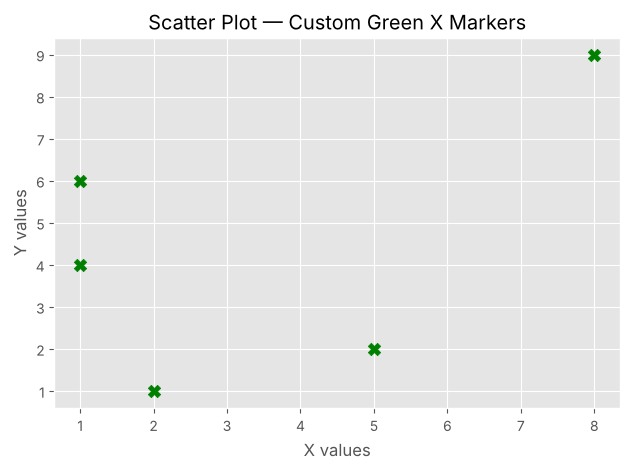

In [2]:
df = pd.DataFrame({"xs": [1, 5, 2, 8, 1], "ys": [4, 2, 1, 9, 6]})

ax = df.plot.scatter(
    x="xs",
    y="ys",
    color="green",
    marker="X",
    s=80,
    title="Scatter Plot — Custom Green X Markers",
)
ax.set_xlabel("X values")
ax.set_ylabel("Y values")
plt.tight_layout()
plt.savefig("chart1_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

**Key point:** `marker='X'` and `color='green'` are passed through the pandas `.plot` API directly to matplotlib. `s=80` controls marker size. The figure is also saved to a PNG file with `savefig()`, so it can be reused outside the notebook.

---
## Chart 2 — Bubble Chart: Four-Variable Encoding

**Task:** Visualize four variables simultaneously in a single chart.

**Encoding:**
- **x-axis** → `hours_in` (time at work)
- **y-axis** → `productivity` (output score)
- **bubble size** → `happiness` × 20 (amplified for visibility)
- **color** → `caffeinated` (0 = no coffee, 1 = coffee)

This is the same technique used in BI dashboards to show KPI relationships across multiple dimensions in one view.

**Dataset:** 13 days of Bill's self-reported work performance data.

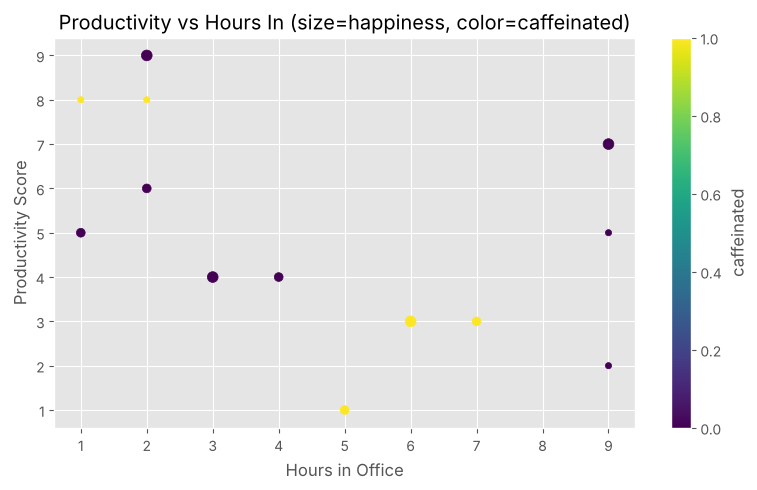

In [3]:
df = pd.DataFrame({
    "productivity": [5, 2, 3, 1, 4, 5, 6, 7, 8, 3, 4, 8, 9],
    "hours_in":     [1, 9, 6, 5, 3, 9, 2, 9, 1, 7, 4, 2, 2],
    "happiness":    [2, 1, 3, 2, 3, 1, 2, 3, 1, 2, 2, 1, 3],
    "caffeinated":  [0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0]
})

ax = df.plot.scatter(
    x="hours_in",
    y="productivity",
    s=df["happiness"] * 20,   # bubble size encodes happiness
    c="caffeinated",          # color encodes caffeination (0 or 1)
    cmap="viridis",
    title="Productivity vs Hours In (size=happiness, color=caffeinated)",
    colorbar=True,
    figsize=(8, 5),
)
ax.set_xlabel("Hours in Office")
ax.set_ylabel("Productivity Score")
plt.tight_layout()
plt.savefig("chart2_bubble.png", dpi=150, bbox_inches="tight")
plt.show()

**Visual interpretation:** The colorbar shows caffeination (0=purple, 1=yellow). Larger bubbles indicate higher happiness. Four dimensions of data are communicated in a single figure — a core skill in dashboard design.

**Design note:** Happiness values were multiplied by 20 (`s=df['happiness'] * 20`) because raw values of 1–3 are too small to perceive as meaningful size differences in a scatter plot.

---
## Chart 3 — Dual-Axis Chart: Revenue and Advertising Spend

**Task:** Plot monthly revenue (bars) and advertising spend (line) on the same figure with separate y-axes.

**Technique:** A dual-axis chart is used when two metrics have different units or scales but need to be compared over the same time period. The `secondary_y=True` parameter creates a right-hand y-axis, and `ax=ax` layers both charts on the same figure.

This pattern is standard in business analytics — comparing sales volume against marketing spend, traffic against conversions, or headcount against costs.

**Dataset:** 12 months of synthetic revenue and advertising data.

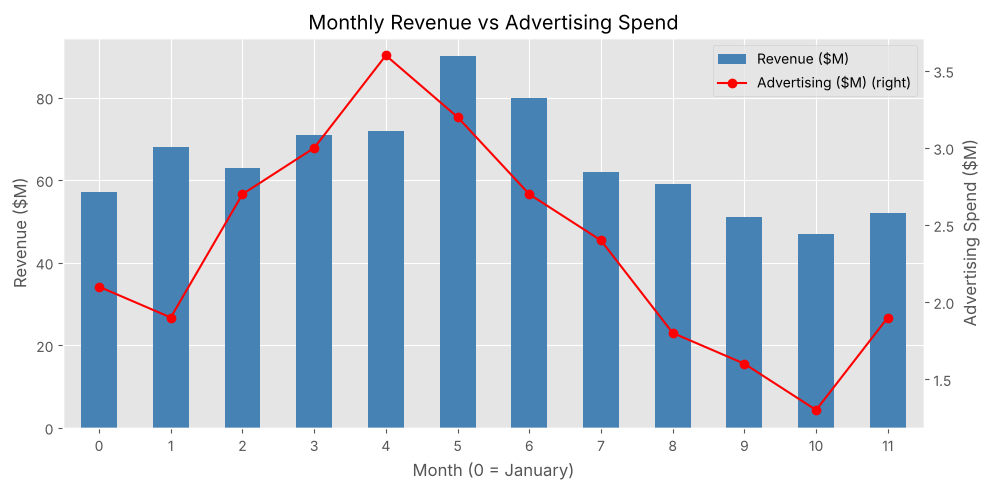

In [4]:
df = pd.DataFrame({
    "revenue":     [57, 68, 63, 71, 72, 90, 80, 62, 59, 51, 47, 52],
    "advertising": [2.1, 1.9, 2.7, 3.0, 3.6, 3.2, 2.7, 2.4, 1.8, 1.6, 1.3, 1.9],
    "month":       range(12)
})

# Layer bar chart and line chart on same figure using ax=ax
ax = df.plot.bar(
    x="month",
    y="revenue",
    color="steelblue",
    label="Revenue ($M)",
    figsize=(10, 5),
)
df.plot.line(
    x="month",
    y="advertising",
    ax=ax,
    secondary_y=True,        # creates right-hand y-axis
    color="red",
    marker="o",
    label="Advertising ($M)",
)

ax.set_xlabel("Month (0 = January)")
ax.set_ylabel("Revenue ($M)")
ax.right_ax.set_ylabel("Advertising Spend ($M)")
ax.set_title("Monthly Revenue vs Advertising Spend")
plt.tight_layout()
plt.savefig("chart3_dual_axis.png", dpi=150, bbox_inches="tight")
plt.show()

**Visual interpretation:** Advertising spend peaks in month 4 (May) at 3.6, and revenue peaks one month later, in month 5 (June), at 90. Both decline through the second half of the year. The one-month lag is the kind of pattern that would prompt a closer look at advertising's delayed effect. With 12 illustrative data points, it is a hypothesis to test, not evidence of cause and effect.

**Technical note:** `secondary_y=True` creates a second y-axis on the right. Passing `ax=ax` ensures both charts share the same x-axis and figure object rather than creating two separate figures.

---
## Conclusion

| Chart | Technique | Business use case |
|-------|-----------|-------------------|
| Scatter plot | `df.plot.scatter(color, marker)` | Two-variable relationship, custom styling |
| Bubble chart | Size + color encoding | Four-variable KPI comparison |
| Dual-axis | `secondary_y=True`, `ax=ax` | Two metrics on different scales vs time |

**Key pandas `.plot` patterns used:**
- Passing `ax=ax` to layer multiple charts on one figure
- `secondary_y=True` for a right-hand y-axis
- Encoding data as marker size (`s=`) and color (`c=`) with `cmap`
- `plt.savefig()` to save charts for reproducible, shareable output

**Skills demonstrated:** matplotlib customization, multi-variable visual encoding, dual-axis design, pandas `.plot` API, chart interpretation for business analytics.